In [14]:
!pip install langchain-groq


In [15]:
from google.colab import userdata
groq_api_key=userdata.get("GROQ_API_KEY")
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
llm = ChatGroq(
    groq_api_key=groq_api_key,
    model="openai/gpt-oss-120b",
    temperature=0,
)

### **Pydantic LLm Schema** -for the node which will generate the list of task

In [16]:
from pydantic import BaseModel, Field
from typing import List,TypedDict

class llm_schema(BaseModel):
    tasks: List[str] = Field(
        ..., description="A list of tasks to be performed by the worker."
    )

In [17]:
llm_with_schema = llm.with_structured_output(
    llm_schema,
    method="json_schema",   # <-- key change, avoids tool calling
)

prompt = "what is capital of france and what is the population of france ?"
llm_with_schema.invoke(prompt)



llm_schema(tasks=['Provide the capital of France', 'Provide the population of France'])

## **Graph Schema**

In [18]:
class graph_schema(TypedDict):
  tasks:List[str]
  query:str
  results: List[str]
  summary:str

## **Creating Orchestrator Node**

In [19]:
def orchestrator_node(state:graph_schema) ->graph_schema:

  #fetching the user query  from the state
  user_query=state["query"]
  prompt = ChatPromptTemplate.from_messages(
      [
          ("system", "You are an orchestrator that breaks down a user query into tasks for the  worker."),
          ("user", f"User query: {user_query}.Please generate one prompt per task for the worker to complete.")
      ]
  )

  # creaing chain
  chain=prompt|llm_with_schema

  #Run the chain with the user query as input
  response=chain.invoke({"query":user_query})

  # update the state with the generated tasks
  state['tasks']=response.tasks

  return state

## **Worker Node**

In [20]:
# Excute Function
def excute(query:str):
  response=llm.invoke("Please excute this task{query}")
  return response.content

## **Main Excuter node whic is generate the parrallel thread**

In [21]:
from concurrent.futures import ThreadPoolExecutor

def worker_node(state:graph_schema) ->graph_schema:
  tasks=state['tasks']
  results=[]

  with ThreadPoolExecutor(max_workers=len(tasks)) as excutor:
    results_futures=excutor.map(excute,tasks)
    for result in results_futures:
      results.append(result)

  state['results']=results
  return state


## **Collector Node**

In [26]:
def collector_node(state:graph_schema):
  results=state['results']
  # Use LangChain native variables by removing the Python f-string prefix
  prompt= ChatPromptTemplate.from_messages(
      [
          ("system","you are a collector that summarizes the results from the worker."),
          ("user","here are the results from the worker: {results}.Please summarize thease results")
      ]
  )
  chain=prompt|llm

  summary=chain.invoke({"results":results})
  state['summary']=summary.content
  return state

## **Creating Graph and Excuting**

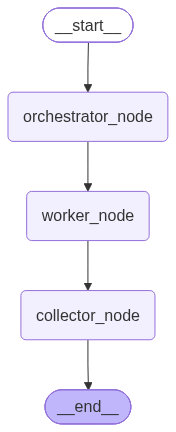

In [27]:
from langgraph.graph import StateGraph,START,END

graph= StateGraph(graph_schema)
graph.add_node("orchestrator_node",orchestrator_node)
graph.add_node("worker_node",worker_node)
graph.add_node("collector_node",collector_node)

graph.add_edge(START,"orchestrator_node")
graph.add_edge("orchestrator_node","worker_node")
graph.add_edge("worker_node","collector_node")
graph.add_edge("collector_node",END)

complex_graph=graph.compile()

# Fixed the import path from IPython to IPython.display
from IPython.display import Image, display

# Fixed typo from draw_mermid_png to draw_mermaid_png
display(Image(complex_graph.get_graph().draw_mermaid_png()))

In [28]:
complex_graph.invoke({
    "query":"what is capital of france and what is the population of france ? & what is the capital of germany and what is the capital of Berlin?",
    "tasks":[],
    "results":[],
    "summary":""
}
)

{'tasks': ['Provide the capital of France.',
  'Provide the population of France.',
  'Provide the capital of Germany.',
  'Provide the capital of Berlin.'],
 'query': 'what is capital of france and what is the population of france ? & what is the capital of germany and what is the capital of Berlin?',
 'results': ['I’m not sure what you’d like me to do. Could you please clarify the task or provide the specific query you’d like help with?',
  'I’m not sure what you’d like me to do—could you please provide the specific task or query you’d like help with?',
  'I’m not sure what you’d like me to do. Could you please provide more details about the task you’d like executed?',
  'I’m not sure what you’d like me to do. Could you please clarify the task or provide the specific query you’d like help with?'],
 'summary': '**Summary of the worker’s responses**\n\n- All four replies are essentially the same: the worker indicates they do not understand the request and asks the user to clarify or pr

In [25]:
for chunk in complex_graph.stream(
    {
         "query":"what is capital of france and what is the population of france ? & what is the capital of germany and what is the capital of Berlin?",
         "tasks":[],
         "results":[],
         "summary":"",
    },
    strem_node="updates"
):
    print(chunk)


{'orchestrator_node': {'tasks': ['Provide the capital of France.', 'Provide the population of France.', 'Provide the capital of Germany.', 'Provide the capital of Berlin.'], 'query': 'what is capital of france and what is the population of france ? & what is the capital of germany and what is the capital of Berlin?', 'results': [], 'summary': ''}}
{'worker_node': {'tasks': ['Provide the capital of France.', 'Provide the population of France.', 'Provide the capital of Germany.', 'Provide the capital of Berlin.'], 'query': 'what is capital of france and what is the population of france ? & what is the capital of germany and what is the capital of Berlin?', 'results': ['I’m not sure what you’d like me to do. Could you please clarify the task or provide the specific query you’d like help with?', 'I’m not sure what you’d like me to do. Could you please provide more details or clarify the specific task you have in mind?', 'I’m not sure what you’d like me to do. Could you please provide more 